In [4]:
import matplotlib.pyplot as plt
import numpy as np

%matplotlib inline

In [5]:
from tensorflow import keras

I0000 00:00:1791983101.100990   79486 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


In [6]:
from tensorflow.keras.preprocessing.image import load_img

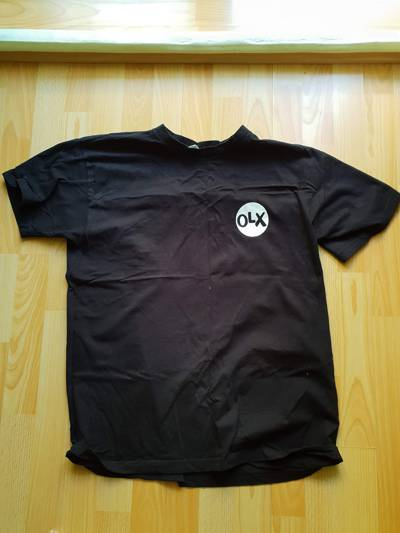

In [4]:
path = "../clothing-dataset-small/train/t-shirt"
name = "5f0a3fa0-6a3d-4b68-b213-72766a643de7.jpg"
fullname = f"{path}/{name}"
load_img(fullname)

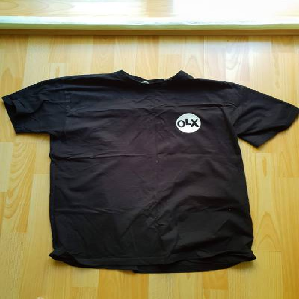

In [5]:
img = load_img(fullname, target_size=(299, 299))
img

In [6]:
x = np.array(img)
x.shape

(299, 299, 3)

Using the Xception model

In [7]:
from tensorflow.keras.applications.xception import (
    Xception,
    decode_predictions,
    preprocess_input,
)

In [8]:
model = Xception(weights="imagenet", input_shape=(299, 299, 3))

I0000 00:00:1791975233.881085   18559 gpu_device.cc:2043] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 3857 MB memory:  -> device: 0, name: NVIDIA GeForce RTX 3060 Ti, pci bus id: 0000:06:00.0, compute capability: 8.6


In [9]:
X = np.array([x])

In [10]:
X.shape

(1, 299, 299, 3)

In [11]:
X = preprocess_input(X)

In [12]:
pred = model.predict(X)

I0000 00:00:1791975236.219528   21023 service.cc:153] XLA service 0x7fcaf8070880 initialized for platform CUDA (this does not guarantee that XLA will be used). Devices:
I0000 00:00:1791975236.219541   21023 service.cc:161]   StreamExecutor [0]: NVIDIA GeForce RTX 3060 Ti, Compute Capability 8.6 (Driver: 13.4.0; Runtime: 12.9.0; Toolkit: 12.5.0; DNN: 9.27.0)
I0000 00:00:1791975236.237840   21023 dump_mlir_util.cc:269] disabling MLIR crash reproducer, set env var `MLIR_CRASH_REPRODUCER_DIRECTORY` to enable.
I0000 00:00:1791975236.504264   21023 cuda_dnn.cc:461] Loaded cuDNN version 92700


1/1 ━━━━━━━━━━━━━━━━━━━━ 5s 5s/step


I0000 00:00:1791975240.952840   21023 device_compiler.h:208] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.


In [13]:
decode_predictions(pred)

[[('n03595614', 'jersey', np.float32(0.681901)),
  ('n02916936', 'bulletproof_vest', np.float32(0.03811864)),
  ('n04370456', 'sweatshirt', np.float32(0.034328133)),
  ('n03710637', 'maillot', np.float32(0.011363347)),
  ('n04525038', 'velvet', np.float32(0.0018467413))]]

Transfer learning

In [8]:
from tensorflow.keras.preprocessing.image import ImageDataGenerator

In [15]:
train_gen = ImageDataGenerator(preprocessing_function=preprocess_input)

train_ds = train_gen.flow_from_directory(
    "../clothing-dataset-small/train", target_size=(150, 150), batch_size=32
)

Found 3068 images belonging to 10 classes.


In [16]:
X, y = next(train_ds)

In [17]:
val_gen = ImageDataGenerator(preprocessing_function=preprocess_input)

val_ds = val_gen.flow_from_directory(
    "../clothing-dataset-small/validation",
    target_size=(150, 150),
    batch_size=32,
    shuffle=False,
)

Found 341 images belonging to 10 classes.


Building the model

In [18]:
base_model = Xception(weights="imagenet", include_top=False, input_shape=(150, 150, 3))

base_model.trainable = False

In [19]:
inputs = keras.Input(shape=(150, 150, 3))

base = base_model(inputs, training=False)

vectors = keras.layers.GlobalAveragePooling2D()(base)

outputs = keras.layers.Dense(10)(vectors)

model = keras.Model(inputs, outputs)

Optimizer and loss

In [20]:
learning_rate = 0.01
optimizer = keras.optimizers.Adam(learning_rate=learning_rate)

In [21]:
loss = keras.losses.CategoricalCrossentropy(from_logits=True)

In [22]:
model.compile(optimizer=optimizer, loss=loss, metrics=["accuracy"])

Training the model

In [23]:
history = model.fit(train_ds, epochs=10, validation_data=val_ds)

Epoch 1/10


I0000 00:00:1791975241.994004   18559 generator_dataset_op.cc:213] Memory patch applied: M_TRIM_THRESHOLD=128 kb was set.
I0000 00:00:1791975244.257559   21021 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_11182__.127
E0000 00:00:1791975245.227463   21021 cuda_timer.cc:87] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
E0000 00:00:1791975246.931848   21021 cuda_timer.cc:87] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.


 3/96 ━━━━━━━━━━━━━━━━━━━━ 3s 38ms/step - accuracy: 0.2708 - loss: 3.5698 

I0000 00:00:1791975249.222513   21023 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_11182__.127
E0000 00:00:1791975251.398415   21023 cuda_timer.cc:87] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.


96/96 ━━━━━━━━━━━━━━━━━━━━ 0s 96ms/step - accuracy: 0.6672 - loss: 1.3120

E0000 00:00:1791975261.492911   21020 cuda_timer.cc:87] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.


96/96 ━━━━━━━━━━━━━━━━━━━━ 21s 155ms/step - accuracy: 0.6672 - loss: 1.3120 - val_accuracy: 0.7859 - val_loss: 0.8091
Epoch 2/10
96/96 ━━━━━━━━━━━━━━━━━━━━ 4s 37ms/step - accuracy: 0.8061 - loss: 0.6703 - val_accuracy: 0.7801 - val_loss: 0.9092
Epoch 3/10
96/96 ━━━━━━━━━━━━━━━━━━━━ 3s 35ms/step - accuracy: 0.8771 - loss: 0.3683 - val_accuracy: 0.7771 - val_loss: 0.9600
Epoch 4/10
96/96 ━━━━━━━━━━━━━━━━━━━━ 4s 42ms/step - accuracy: 0.9091 - loss: 0.2688 - val_accuracy: 0.8035 - val_loss: 0.8726
Epoch 5/10
96/96 ━━━━━━━━━━━━━━━━━━━━ 4s 37ms/step - accuracy: 0.9361 - loss: 0.1691 - val_accuracy: 0.7947 - val_loss: 0.8632
Epoch 6/10
96/96 ━━━━━━━━━━━━━━━━━━━━ 3s 34ms/step - accuracy: 0.9677 - loss: 0.0959 - val_accuracy: 0.8065 - val_loss: 0.8861
Epoch 7/10
96/96 ━━━━━━━━━━━━━━━━━━━━ 4s 40ms/step - accuracy: 0.9733 - loss: 0.0769 - val_accuracy: 0.7947 - val_loss: 0.9241
Epoch 8/10
96/96 ━━━━━━━━━━━━━━━━━━━━ 4s 37ms/step - accuracy: 0.9857 - loss: 0.0511 - val_accuracy: 0.8065 - val_loss: 

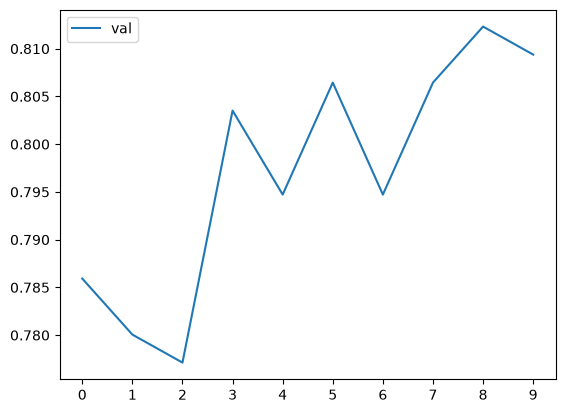

In [24]:
plt.plot(history.history["val_accuracy"], label="val")
plt.xticks(np.arange(10))
plt.legend()

In [25]:
base = base_model(inputs, training=False)

Adjusting the learning rate

In [26]:
def make_model(learning_rate=0.01):
    base_model = Xception(
        weights="imagenet", include_top=False, input_shape=(150, 150, 3)
    )

    base_model.trainable = False

    #########################################

    inputs = keras.Input(shape=(150, 150, 3))
    base = base_model(inputs, training=False)
    vectors = keras.layers.GlobalAveragePooling2D()(base)
    outputs = keras.layers.Dense(10)(vectors)
    model = keras.Model(inputs, outputs)

    #########################################

    optimizer = keras.optimizers.Adam(learning_rate=learning_rate)
    loss = keras.losses.CategoricalCrossentropy(from_logits=True)

    model.compile(optimizer=optimizer, loss=loss, metrics=["accuracy"])

    return model

In [27]:
scores = {}

for lr in [0.0001, 0.001, 0.01, 0.1]:
    print(lr)

    model = make_model(learning_rate=lr)
    history = model.fit(train_ds, epochs=10, validation_data=val_ds)
    scores[lr] = history.history

    print()
    print()

0.0001
Epoch 1/10


I0000 00:00:1791975299.251563   21021 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_25171__.127


78/96 ━━━━━━━━━━━━━━━━━━━━ 0s 32ms/step - accuracy: 0.2853 - loss: 2.0526

I0000 00:00:1791975303.218970   21023 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_25171__.127


96/96 ━━━━━━━━━━━━━━━━━━━━ 11s 76ms/step - accuracy: 0.3106 - loss: 1.9878 - val_accuracy: 0.4457 - val_loss: 1.6406
Epoch 2/10
96/96 ━━━━━━━━━━━━━━━━━━━━ 4s 40ms/step - accuracy: 0.5554 - loss: 1.4088 - val_accuracy: 0.5982 - val_loss: 1.2688
Epoch 3/10
96/96 ━━━━━━━━━━━━━━━━━━━━ 4s 39ms/step - accuracy: 0.6444 - loss: 1.1489 - val_accuracy: 0.6628 - val_loss: 1.0785
Epoch 4/10
96/96 ━━━━━━━━━━━━━━━━━━━━ 4s 45ms/step - accuracy: 0.6825 - loss: 1.0030 - val_accuracy: 0.6921 - val_loss: 0.9635
Epoch 5/10
96/96 ━━━━━━━━━━━━━━━━━━━━ 4s 44ms/step - accuracy: 0.7115 - loss: 0.9057 - val_accuracy: 0.7155 - val_loss: 0.8900
Epoch 6/10
96/96 ━━━━━━━━━━━━━━━━━━━━ 5s 49ms/step - accuracy: 0.7311 - loss: 0.8389 - val_accuracy: 0.7331 - val_loss: 0.8415
Epoch 7/10
96/96 ━━━━━━━━━━━━━━━━━━━━ 5s 51ms/step - accuracy: 0.7432 - loss: 0.7848 - val_accuracy: 0.7449 - val_loss: 0.8035
Epoch 8/10
96/96 ━━━━━━━━━━━━━━━━━━━━ 5s 48ms/step - accuracy: 0.7624 - loss: 0.7428 - val_accuracy: 0.7449 - val_loss: 0

...

96/96 ━━━━━━━━━━━━━━━━━━━━ 12s 84ms/step - accuracy: 0.6851 - loss: 1.2410 - val_accuracy: 0.7361 - val_loss: 1.0493
Epoch 2/10
96/96 ━━━━━━━━━━━━━━━━━━━━ 4s 45ms/step - accuracy: 0.8142 - loss: 0.6114 - val_accuracy: 0.7830 - val_loss: 1.0329
Epoch 3/10
96/96 ━━━━━━━━━━━━━━━━━━━━ 4s 38ms/step - accuracy: 0.8970 - loss: 0.2966 - val_accuracy: 0.8416 - val_loss: 0.6789
Epoch 4/10
96/96 ━━━━━━━━━━━━━━━━━━━━ 4s 41ms/step - accuracy: 0.9224 - loss: 0.2160 - val_accuracy: 0.7830 - val_loss: 0.8580
Epoch 5/10
96/96 ━━━━━━━━━━━━━━━━━━━━ 4s 46ms/step - accuracy: 0.9306 - loss: 0.1944 - val_accuracy: 0.7977 - val_loss: 0.9408
Epoch 6/10
96/96 ━━━━━━━━━━━━━━━━━━━━ 4s 41ms/step - accuracy: 0.9534 - loss: 0.1386 - val_accuracy: 0.8035 - val_loss: 0.9073
Epoch 7/10
96/96 ━━━━━━━━━━━━━━━━━━━━ 4s 41ms/step - accuracy: 0.9612 - loss: 0.1096 - val_accuracy: 0.7654 - val_loss: 0.9793
Epoch 8/10
96/96 ━━━━━━━━━━━━━━━━━━━━ 4s 43ms/step - accuracy: 0.9671 - loss: 0.1036 - val_accuracy: 0.7889 - val_loss: 1

I0000 00:00:1791975448.791692   21021 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_67138__.127


 6/96 ━━━━━━━━━━━━━━━━━━━━ 3s 44ms/step - accuracy: 0.3698 - loss: 28.7672

I0000 00:00:1791975450.538525   21021 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_67138__.127


96/96 ━━━━━━━━━━━━━━━━━━━━ 11s 81ms/step - accuracy: 0.6274 - loss: 11.9126 - val_accuracy: 0.6862 - val_loss: 9.1087
Epoch 2/10
96/96 ━━━━━━━━━━━━━━━━━━━━ 4s 44ms/step - accuracy: 0.7839 - loss: 5.0992 - val_accuracy: 0.7449 - val_loss: 8.3538
Epoch 3/10
96/96 ━━━━━━━━━━━━━━━━━━━━ 4s 45ms/step - accuracy: 0.8113 - loss: 4.3924 - val_accuracy: 0.7771 - val_loss: 6.8187
Epoch 4/10
96/96 ━━━━━━━━━━━━━━━━━━━━ 4s 41ms/step - accuracy: 0.8752 - loss: 2.3804 - val_accuracy: 0.7683 - val_loss: 7.4001
Epoch 5/10
96/96 ━━━━━━━━━━━━━━━━━━━━ 5s 47ms/step - accuracy: 0.8944 - loss: 1.9489 - val_accuracy: 0.7595 - val_loss: 10.0753
Epoch 6/10
96/96 ━━━━━━━━━━━━━━━━━━━━ 4s 42ms/step - accuracy: 0.9084 - loss: 1.7766 - val_accuracy: 0.7478 - val_loss: 9.7277
Epoch 7/10
96/96 ━━━━━━━━━━━━━━━━━━━━ 4s 43ms/step - accuracy: 0.9113 - loss: 1.6456 - val_accuracy: 0.7449 - val_loss: 12.4616
Epoch 8/10
96/96 ━━━━━━━━━━━━━━━━━━━━ 4s 45ms/step - accuracy: 0.9074 - loss: 1.9803 - val_accuracy: 0.7859 - val_loss

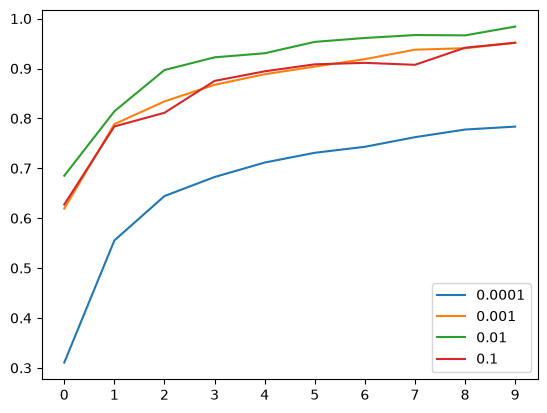

In [28]:
for lr, hist in scores.items():
    plt.plot(hist["accuracy"], label=lr)

plt.xticks(np.arange(10))
plt.legend()

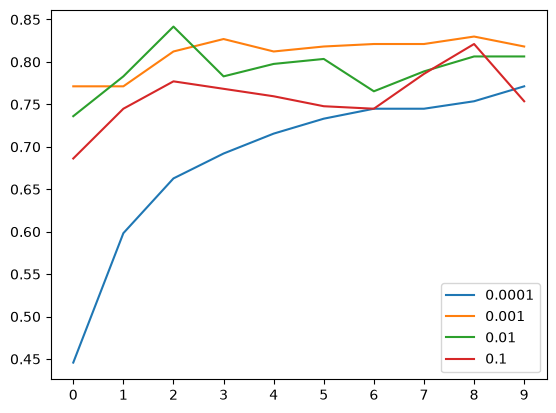

In [29]:
for lr, hist in scores.items():
    plt.plot(hist["val_accuracy"], label=lr)

plt.xticks(np.arange(10))
plt.legend()

In [30]:
del scores[0.1]
del scores[0.0001]

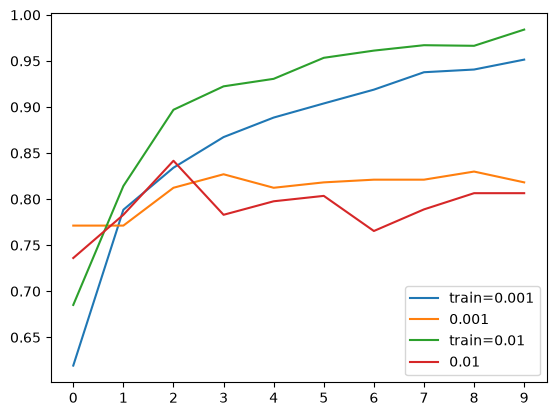

In [31]:
for lr, hist in scores.items():
    plt.plot(hist["accuracy"], label=("train=%s" % lr))
    plt.plot(hist["val_accuracy"], label=lr)

plt.xticks(np.arange(10))
plt.legend()

In [32]:
learning_rate = 0.001

Checkpointing

In [33]:
model.save_weights("model_v1.weights.h5")

In [34]:
checkpoint = keras.callbacks.ModelCheckpoint(
    "xception_v1_{epoch:02d}_{val_accuracy:.3f}.weights.h5",
    save_best_only=True,
    monitor="val_accuracy",
    mode="max",
)

Training with a callback

In [35]:
learning_rate = 0.001

model = make_model(learning_rate=learning_rate)

history = model.fit(train_ds, epochs=10, validation_data=val_ds, callbacks=[checkpoint])

Epoch 1/10


I0000 00:00:1791975500.560271   21022 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_81618__.127


35/96 ━━━━━━━━━━━━━━━━━━━━ 2s 40ms/step - accuracy: 0.5071 - loss: 1.4928

I0000 00:00:1791975503.583637   21020 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_81618__.127


95/96 ━━━━━━━━━━━━━━━━━━━━ 0s 55ms/step - accuracy: 0.6281 - loss: 1.0996

96/96 ━━━━━━━━━━━━━━━━━━━━ 13s 94ms/step - accuracy: 0.6287 - loss: 1.1001 - val_accuracy: 0.7801 - val_loss: 0.6950
Epoch 2/10
95/96 ━━━━━━━━━━━━━━━━━━━━ 0s 45ms/step - accuracy: 0.7849 - loss: 0.6248

96/96 ━━━━━━━━━━━━━━━━━━━━ 5s 56ms/step - accuracy: 0.7852 - loss: 0.6251 - val_accuracy: 0.8065 - val_loss: 0.6128
Epoch 3/10
95/96 ━━━━━━━━━━━━━━━━━━━━ 0s 36ms/step - accuracy: 0.8340 - loss: 0.5103

96/96 ━━━━━━━━━━━━━━━━━━━━ 5s 47ms/step - accuracy: 0.8338 - loss: 0.5102 - val_accuracy: 0.8270 - val_loss: 0.5662
Epoch 4/10
96/96 ━━━━━━━━━━━━━━━━━━━━ 4s 46ms/step - accuracy: 0.8615 - loss: 0.4305 - val_accuracy: 0.8035 - val_loss: 0.5912
Epoch 5/10
95/96 ━━━━━━━━━━━━━━━━━━━━ 0s 45ms/step - accuracy: 0.8880 - loss: 0.3712

96/96 ━━━━━━━━━━━━━━━━━━━━ 5s 54ms/step - accuracy: 0.8869 - loss: 0.3732 - val_accuracy: 0.8446 - val_loss: 0.5243
Epoch 6/10
96/96 ━━━━━━━━━━━━━━━━━━━━ 4s 38ms/step - accuracy: 0.9051 - loss: 0.3292 - val_accuracy: 0.8328 - val_loss: 0.5214
Epoch 7/10
96/96 ━━━━━━━━━━━━━━━━━━━━ 4s 46ms/step - accuracy: 0.9162 - loss: 0.2971 - val_accuracy: 0.8182 - val_loss: 0.5334
Epoch 8/10
96/96 ━━━━━━━━━━━━━━━━━━━━ 5s 48ms/step - accuracy: 0.9351 - loss: 0.2566 - val_accuracy: 0.8299 - val_loss: 0.5232
Epoch 9/10
96/96 ━━━━━━━━━━━━━━━━━━━━ 4s 38ms/step - accuracy: 0.9472 - loss: 0.2308 - val_accuracy: 0.8270 - val_loss: 0.5268
Epoch 10/10
96/96 ━━━━━━━━━━━━━━━━━━━━ 4s 45ms/step - accuracy: 0.9534 - loss: 0.2113 - val_accuracy: 0.8182 - val_loss: 0.5413


Adding more layers

In [36]:
def make_model(learning_rate=0.01, size_inner=100):
    base_model = Xception(
        weights="imagenet", include_top=False, input_shape=(150, 150, 3)
    )

    base_model.trainable = False

    #########################################

    inputs = keras.Input(shape=(150, 150, 3))
    base = base_model(inputs, training=False)
    vectors = keras.layers.GlobalAveragePooling2D()(base)

    inner = keras.layers.Dense(size_inner, activation="relu")(vectors)

    outputs = keras.layers.Dense(10)(inner)

    model = keras.Model(inputs, outputs)

    #########################################

    optimizer = keras.optimizers.Adam(learning_rate=learning_rate)
    loss = keras.losses.CategoricalCrossentropy(from_logits=True)

    model.compile(optimizer=optimizer, loss=loss, metrics=["accuracy"])

    return model

In [39]:
learning_rate = 0.001

scores = {}

for size in [10, 100, 1000]:
    print(size)

    model = make_model(learning_rate=learning_rate, size_inner=size)
    history = model.fit(train_ds, epochs=10, validation_data=val_ds)
    scores[size] = history.history

    print()
    print()

10
Epoch 1/10


I0000 00:00:1791975857.010399   21020 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_140790__.128


65/96 ━━━━━━━━━━━━━━━━━━━━ 1s 34ms/step - accuracy: 0.4639 - loss: 1.6478

I0000 00:00:1791975860.984852   21022 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_140790__.128


96/96 ━━━━━━━━━━━━━━━━━━━━ 11s 81ms/step - accuracy: 0.5163 - loss: 1.4703 - val_accuracy: 0.6657 - val_loss: 1.0363
Epoch 2/10
96/96 ━━━━━━━━━━━━━━━━━━━━ 3s 32ms/step - accuracy: 0.7239 - loss: 0.8764 - val_accuracy: 0.7478 - val_loss: 0.7909
Epoch 3/10
96/96 ━━━━━━━━━━━━━━━━━━━━ 4s 38ms/step - accuracy: 0.7744 - loss: 0.6847 - val_accuracy: 0.7595 - val_loss: 0.7374
Epoch 4/10
96/96 ━━━━━━━━━━━━━━━━━━━━ 3s 32ms/step - accuracy: 0.8070 - loss: 0.5843 - val_accuracy: 0.7771 - val_loss: 0.6635
Epoch 5/10
96/96 ━━━━━━━━━━━━━━━━━━━━ 3s 32ms/step - accuracy: 0.8360 - loss: 0.5008 - val_accuracy: 0.7801 - val_loss: 0.6445
Epoch 6/10
96/96 ━━━━━━━━━━━━━━━━━━━━ 4s 39ms/step - accuracy: 0.8690 - loss: 0.4326 - val_accuracy: 0.7742 - val_loss: 0.6559
Epoch 7/10
96/96 ━━━━━━━━━━━━━━━━━━━━ 3s 34ms/step - accuracy: 0.8836 - loss: 0.3868 - val_accuracy: 0.7683 - val_loss: 0.6387
Epoch 8/10
96/96 ━━━━━━━━━━━━━━━━━━━━ 3s 32ms/step - accuracy: 0.9071 - loss: 0.3350 - val_accuracy: 0.7947 - val_loss: 0

...

96/96 ━━━━━━━━━━━━━━━━━━━━ 12s 83ms/step - accuracy: 0.6675 - loss: 0.9927 - val_accuracy: 0.7713 - val_loss: 0.7460
Epoch 2/10
96/96 ━━━━━━━━━━━━━━━━━━━━ 5s 42ms/step - accuracy: 0.8096 - loss: 0.5266 - val_accuracy: 0.7918 - val_loss: 0.5840
Epoch 3/10
96/96 ━━━━━━━━━━━━━━━━━━━━ 4s 38ms/step - accuracy: 0.8729 - loss: 0.3720 - val_accuracy: 0.8035 - val_loss: 0.5736
Epoch 4/10
96/96 ━━━━━━━━━━━━━━━━━━━━ 4s 39ms/step - accuracy: 0.9149 - loss: 0.2729 - val_accuracy: 0.8240 - val_loss: 0.5683
Epoch 5/10
96/96 ━━━━━━━━━━━━━━━━━━━━ 4s 43ms/step - accuracy: 0.9430 - loss: 0.1979 - val_accuracy: 0.8123 - val_loss: 0.6351
Epoch 6/10
96/96 ━━━━━━━━━━━━━━━━━━━━ 4s 37ms/step - accuracy: 0.9615 - loss: 0.1424 - val_accuracy: 0.8035 - val_loss: 0.6171
Epoch 7/10
96/96 ━━━━━━━━━━━━━━━━━━━━ 4s 40ms/step - accuracy: 0.9847 - loss: 0.0966 - val_accuracy: 0.8065 - val_loss: 0.5984
Epoch 8/10
96/96 ━━━━━━━━━━━━━━━━━━━━ 4s 40ms/step - accuracy: 0.9873 - loss: 0.0773 - val_accuracy: 0.8270 - val_loss: 0

I0000 00:00:1791975948.430821   21021 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_169414__.128


42/96 ━━━━━━━━━━━━━━━━━━━━ 1s 34ms/step - accuracy: 0.6198 - loss: 1.1466

I0000 00:00:1791975951.562529   21022 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_169414__.128


96/96 ━━━━━━━━━━━━━━━━━━━━ 12s 82ms/step - accuracy: 0.6786 - loss: 0.9456 - val_accuracy: 0.8035 - val_loss: 0.6024
Epoch 2/10
96/96 ━━━━━━━━━━━━━━━━━━━━ 4s 37ms/step - accuracy: 0.8556 - loss: 0.4335 - val_accuracy: 0.7771 - val_loss: 0.6094
Epoch 3/10
96/96 ━━━━━━━━━━━━━━━━━━━━ 4s 41ms/step - accuracy: 0.9097 - loss: 0.2730 - val_accuracy: 0.8328 - val_loss: 0.5567
Epoch 4/10
96/96 ━━━━━━━━━━━━━━━━━━━━ 4s 37ms/step - accuracy: 0.9557 - loss: 0.1455 - val_accuracy: 0.8182 - val_loss: 0.5756
Epoch 5/10
96/96 ━━━━━━━━━━━━━━━━━━━━ 4s 38ms/step - accuracy: 0.9827 - loss: 0.0737 - val_accuracy: 0.8006 - val_loss: 0.6111
Epoch 6/10
96/96 ━━━━━━━━━━━━━━━━━━━━ 4s 45ms/step - accuracy: 0.9860 - loss: 0.0579 - val_accuracy: 0.8211 - val_loss: 0.6450
Epoch 7/10
96/96 ━━━━━━━━━━━━━━━━━━━━ 3s 33ms/step - accuracy: 0.9974 - loss: 0.0251 - val_accuracy: 0.8182 - val_loss: 0.6925
Epoch 8/10
96/96 ━━━━━━━━━━━━━━━━━━━━ 4s 38ms/step - accuracy: 0.9990 - loss: 0.0146 - val_accuracy: 0.8152 - val_loss: 0

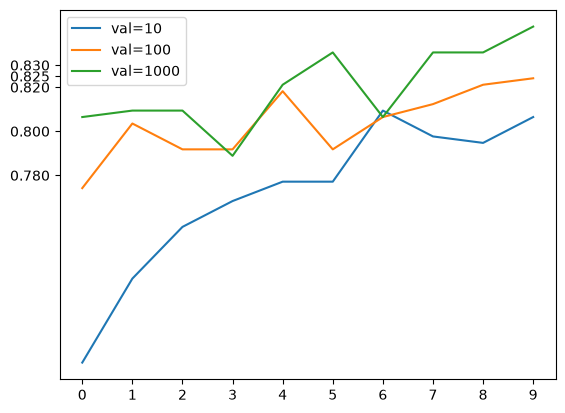

In [38]:
for size, hist in scores.items():
    plt.plot(hist["val_accuracy"], label=("val=%s" % size))

plt.xticks(np.arange(10))
plt.yticks([0.78, 0.80, 0.82, 0.825, 0.83])
plt.legend()

Dropout

In [40]:
def make_model(learning_rate=0.01, size_inner=100, droprate=0.5):
    base_model = Xception(
        weights="imagenet", include_top=False, input_shape=(150, 150, 3)
    )

    base_model.trainable = False

    #########################################

    inputs = keras.Input(shape=(150, 150, 3))
    base = base_model(inputs, training=False)
    vectors = keras.layers.GlobalAveragePooling2D()(base)

    inner = keras.layers.Dense(size_inner, activation="relu")(vectors)
    drop = keras.layers.Dropout(droprate)(inner)

    outputs = keras.layers.Dense(10)(drop)

    model = keras.Model(inputs, outputs)

    #########################################

    optimizer = keras.optimizers.Adam(learning_rate=learning_rate)
    loss = keras.losses.CategoricalCrossentropy(from_logits=True)

    model.compile(optimizer=optimizer, loss=loss, metrics=["accuracy"])

    return model

In [41]:
learning_rate = 0.001
size = 100

scores = {}

for droprate in [0.0, 0.2, 0.5, 0.8]:
    print(droprate)

    model = make_model(learning_rate=learning_rate, size_inner=size, droprate=droprate)

    history = model.fit(train_ds, epochs=30, validation_data=val_ds)
    scores[droprate] = history.history

    print()
    print()

0.0
Epoch 1/30


I0000 00:00:1791976852.268219   21019 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_183722__.128


43/96 ━━━━━━━━━━━━━━━━━━━━ 1s 32ms/step - accuracy: 0.5938 - loss: 1.2086

I0000 00:00:1791976855.472065   21022 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_183722__.128


96/96 ━━━━━━━━━━━━━━━━━━━━ 12s 81ms/step - accuracy: 0.6708 - loss: 0.9594 - val_accuracy: 0.7859 - val_loss: 0.6573
Epoch 2/30
96/96 ━━━━━━━━━━━━━━━━━━━━ 4s 38ms/step - accuracy: 0.8145 - loss: 0.5225 - val_accuracy: 0.7771 - val_loss: 0.6199
Epoch 3/30
96/96 ━━━━━━━━━━━━━━━━━━━━ 3s 34ms/step - accuracy: 0.8810 - loss: 0.3559 - val_accuracy: 0.8123 - val_loss: 0.5693
Epoch 4/30
96/96 ━━━━━━━━━━━━━━━━━━━━ 4s 42ms/step - accuracy: 0.9195 - loss: 0.2576 - val_accuracy: 0.8065 - val_loss: 0.6042
Epoch 5/30
96/96 ━━━━━━━━━━━━━━━━━━━━ 4s 41ms/step - accuracy: 0.9495 - loss: 0.1798 - val_accuracy: 0.8065 - val_loss: 0.5906
Epoch 6/30
96/96 ━━━━━━━━━━━━━━━━━━━━ 3s 34ms/step - accuracy: 0.9729 - loss: 0.1205 - val_accuracy: 0.8182 - val_loss: 0.5705
Epoch 7/30
96/96 ━━━━━━━━━━━━━━━━━━━━ 4s 43ms/step - accuracy: 0.9870 - loss: 0.0868 - val_accuracy: 0.8211 - val_loss: 0.5457
Epoch 8/30
96/96 ━━━━━━━━━━━━━━━━━━━━ 4s 38ms/step - accuracy: 0.9925 - loss: 0.0643 - val_accuracy: 0.8182 - val_loss: 0

...

96/96 ━━━━━━━━━━━━━━━━━━━━ 13s 88ms/step - accuracy: 0.5786 - loss: 1.2921 - val_accuracy: 0.7449 - val_loss: 0.8014
Epoch 2/30
96/96 ━━━━━━━━━━━━━━━━━━━━ 3s 33ms/step - accuracy: 0.7112 - loss: 0.8332 - val_accuracy: 0.7742 - val_loss: 0.6663
Epoch 3/30
96/96 ━━━━━━━━━━━━━━━━━━━━ 4s 37ms/step - accuracy: 0.7546 - loss: 0.6939 - val_accuracy: 0.7859 - val_loss: 0.6045
Epoch 4/30
96/96 ━━━━━━━━━━━━━━━━━━━━ 3s 32ms/step - accuracy: 0.8002 - loss: 0.5781 - val_accuracy: 0.8358 - val_loss: 0.5549
Epoch 5/30
96/96 ━━━━━━━━━━━━━━━━━━━━ 3s 31ms/step - accuracy: 0.8158 - loss: 0.5267 - val_accuracy: 0.7859 - val_loss: 0.5734
Epoch 6/30
96/96 ━━━━━━━━━━━━━━━━━━━━ 4s 37ms/step - accuracy: 0.8426 - loss: 0.4522 - val_accuracy: 0.8211 - val_loss: 0.5373
Epoch 7/30
96/96 ━━━━━━━━━━━━━━━━━━━━ 3s 33ms/step - accuracy: 0.8537 - loss: 0.4189 - val_accuracy: 0.8211 - val_loss: 0.5220
Epoch 8/30
96/96 ━━━━━━━━━━━━━━━━━━━━ 3s 33ms/step - accuracy: 0.8768 - loss: 0.3622 - val_accuracy: 0.8416 - val_loss: 0

I0000 00:00:1791977209.323002   21021 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_254028__.129


93/96 ━━━━━━━━━━━━━━━━━━━━ 0s 40ms/step - accuracy: 0.3918 - loss: 1.7967

I0000 00:00:1791977214.981538   21019 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_254028__.129


96/96 ━━━━━━━━━━━━━━━━━━━━ 13s 93ms/step - accuracy: 0.3928 - loss: 1.7904 - val_accuracy: 0.6950 - val_loss: 1.1426
Epoch 2/30
96/96 ━━━━━━━━━━━━━━━━━━━━ 4s 38ms/step - accuracy: 0.5251 - loss: 1.3827 - val_accuracy: 0.7361 - val_loss: 0.9290
Epoch 3/30
96/96 ━━━━━━━━━━━━━━━━━━━━ 3s 32ms/step - accuracy: 0.5668 - loss: 1.2723 - val_accuracy: 0.7478 - val_loss: 0.8416
Epoch 4/30
96/96 ━━━━━━━━━━━━━━━━━━━━ 4s 38ms/step - accuracy: 0.5766 - loss: 1.1935 - val_accuracy: 0.7859 - val_loss: 0.7823
Epoch 5/30
96/96 ━━━━━━━━━━━━━━━━━━━━ 4s 38ms/step - accuracy: 0.6089 - loss: 1.1086 - val_accuracy: 0.7830 - val_loss: 0.7415
Epoch 6/30
96/96 ━━━━━━━━━━━━━━━━━━━━ 3s 31ms/step - accuracy: 0.6147 - loss: 1.0726 - val_accuracy: 0.7889 - val_loss: 0.7060
Epoch 7/30
96/96 ━━━━━━━━━━━━━━━━━━━━ 4s 40ms/step - accuracy: 0.6330 - loss: 1.0006 - val_accuracy: 0.7889 - val_loss: 0.6869
Epoch 8/30
96/96 ━━━━━━━━━━━━━━━━━━━━ 4s 37ms/step - accuracy: 0.6477 - loss: 0.9757 - val_accuracy: 0.8006 - val_loss: 0

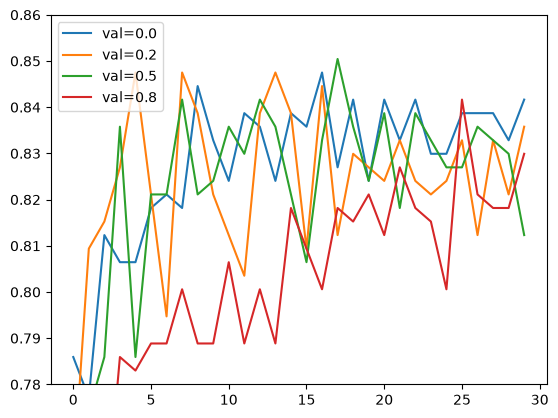

In [42]:
for droprate, hist in scores.items():
    plt.plot(hist["val_accuracy"], label=("val=%s" % droprate))

plt.ylim(0.78, 0.86)
plt.legend()

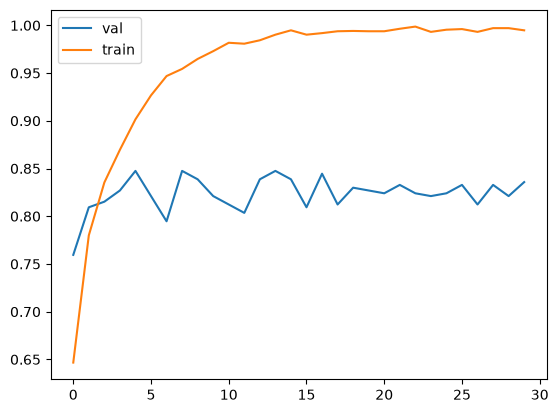

In [44]:
hist = scores[0.2]
plt.plot(hist["val_accuracy"], label="val")
plt.plot(hist["accuracy"], label="train")

plt.legend()

Data augmentation

In [51]:
train_gen = ImageDataGenerator(
    preprocessing_function=preprocess_input,
    shear_range=10.0,
    zoom_range=0.1,
    vertical_flip=True,
)

train_ds = train_gen.flow_from_directory(
    "../clothing-dataset-small/train", target_size=(150, 150), batch_size=32
)

val_gen = ImageDataGenerator(preprocessing_function=preprocess_input)

val_ds = val_gen.flow_from_directory(
    "../clothing-dataset-small/validation",
    target_size=(150, 150),
    batch_size=32,
    shuffle=False,
)

Found 3068 images belonging to 10 classes.
Found 341 images belonging to 10 classes.


In [52]:
learning_rate = 0.001
size = 100
droprate = 0.2

model = make_model(learning_rate=learning_rate, size_inner=size, droprate=droprate)

history = model.fit(train_ds, epochs=50, validation_data=val_ds)

Epoch 1/50


I0000 00:00:1791981598.670633   21019 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_342416__.129


82/96 ━━━━━━━━━━━━━━━━━━━━ 1s 98ms/step - accuracy: 0.5633 - loss: 1.3095

I0000 00:00:1791981609.012606   21022 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_342416__.129


96/96 ━━━━━━━━━━━━━━━━━━━━ 19s 155ms/step - accuracy: 0.5743 - loss: 1.2736 - val_accuracy: 0.7566 - val_loss: 0.7291
Epoch 2/50
96/96 ━━━━━━━━━━━━━━━━━━━━ 10s 99ms/step - accuracy: 0.7027 - loss: 0.8948 - val_accuracy: 0.7390 - val_loss: 0.7433
Epoch 3/50
96/96 ━━━━━━━━━━━━━━━━━━━━ 9s 98ms/step - accuracy: 0.7379 - loss: 0.7751 - val_accuracy: 0.7801 - val_loss: 0.6548
Epoch 4/50
96/96 ━━━━━━━━━━━━━━━━━━━━ 10s 103ms/step - accuracy: 0.7568 - loss: 0.7015 - val_accuracy: 0.7830 - val_loss: 0.6541
Epoch 5/50
96/96 ━━━━━━━━━━━━━━━━━━━━ 10s 102ms/step - accuracy: 0.7891 - loss: 0.6247 - val_accuracy: 0.7918 - val_loss: 0.6326
Epoch 6/50
96/96 ━━━━━━━━━━━━━━━━━━━━ 9s 94ms/step - accuracy: 0.7927 - loss: 0.5963 - val_accuracy: 0.7830 - val_loss: 0.5966
Epoch 7/50
96/96 ━━━━━━━━━━━━━━━━━━━━ 10s 105ms/step - accuracy: 0.8070 - loss: 0.5552 - val_accuracy: 0.8006 - val_loss: 0.6336
Epoch 8/50
96/96 ━━━━━━━━━━━━━━━━━━━━ 10s 107ms/step - accuracy: 0.8207 - loss: 0.5269 - val_accuracy: 0.7977 - v

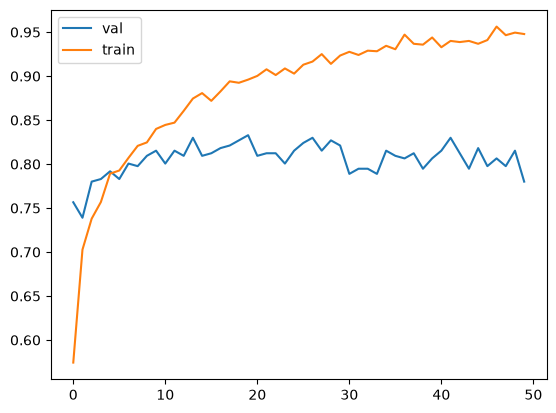

In [53]:
hist = history.history
plt.plot(hist["val_accuracy"], label="val")
plt.plot(hist["accuracy"], label="train")

plt.legend()

Training a larger model

In [1]:
def make_model(input_size=150, learning_rate=0.01, size_inner=100, droprate=0.5):

    base_model = Xception(
        weights="imagenet", include_top=False, input_shape=(input_size, input_size, 3)
    )

    base_model.trainable = False

    #########################################

    inputs = keras.Input(shape=(input_size, input_size, 3))
    base = base_model(inputs, training=False)
    vectors = keras.layers.GlobalAveragePooling2D()(base)

    inner = keras.layers.Dense(size_inner, activation="relu")(vectors)
    drop = keras.layers.Dropout(droprate)(inner)

    outputs = keras.layers.Dense(10)(drop)

    model = keras.Model(inputs, outputs)

    #########################################

    optimizer = keras.optimizers.Adam(learning_rate=learning_rate)
    loss = keras.losses.CategoricalCrossentropy(from_logits=True)

    model.compile(optimizer=optimizer, loss=loss, metrics=["accuracy"])

    return model

In [2]:
input_size = 299

In [9]:
train_gen = ImageDataGenerator(
    preprocessing_function=preprocess_input,
    shear_range=10,
    zoom_range=0.1,
    horizontal_flip=True,
)

train_ds = train_gen.flow_from_directory(
    "../clothing-dataset-small/train",
    target_size=(input_size, input_size),
    batch_size=32,
)


val_gen = ImageDataGenerator(preprocessing_function=preprocess_input)

val_ds = val_gen.flow_from_directory(
    "../clothing-dataset-small/validation",
    target_size=(input_size, input_size),
    batch_size=32,
    shuffle=False,
)

Found 3068 images belonging to 10 classes.
Found 341 images belonging to 10 classes.


In [10]:
checkpoint = keras.callbacks.ModelCheckpoint(
    "xception_v4_1_{epoch:02d}_{val_accuracy:.3f}.h5",
    save_best_only=True,
    monitor="val_accuracy",
    mode="max",
)

In [11]:
learning_rate = 0.0005
size = 100
droprate = 0.2

model = make_model(
    input_size=input_size,
    learning_rate=learning_rate,
    size_inner=size,
    droprate=droprate,
)

history = model.fit(train_ds, epochs=50, validation_data=val_ds, callbacks=[checkpoint])

I0000 00:00:1791983137.609078   79486 gpu_device.cc:2043] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 3768 MB memory:  -> device: 0, name: NVIDIA GeForce RTX 3060 Ti, pci bus id: 0000:06:00.0, compute capability: 8.6


Epoch 1/50


I0000 00:00:1791983139.550290   79486 generator_dataset_op.cc:213] Memory patch applied: M_TRIM_THRESHOLD=128 kb was set.
I0000 00:00:1791983141.659493   79762 service.cc:153] XLA service 0x7fbf8c066ce0 initialized for platform CUDA (this does not guarantee that XLA will be used). Devices:
I0000 00:00:1791983141.659509   79762 service.cc:161]   StreamExecutor [0]: NVIDIA GeForce RTX 3060 Ti, Compute Capability 8.6 (Driver: 13.4.0; Runtime: 12.9.0; Toolkit: 12.5.0; DNN: 9.27.0)
I0000 00:00:1791983141.710287   79762 dump_mlir_util.cc:269] disabling MLIR crash reproducer, set env var `MLIR_CRASH_REPRODUCER_DIRECTORY` to enable.
I0000 00:00:1791983142.272851   79762 cuda_dnn.cc:461] Loaded cuDNN version 92700
I0000 00:00:1791983142.320048   79762 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_7724__.129
E0000 00:00:1791983144.888505   79762 cuda_timer.cc:87] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution

55/96 ━━━━━━━━━━━━━━━━━━━━ 12s 311ms/step - accuracy: 0.5858 - loss: 1.2668

I0000 00:00:1791983180.207197   79766 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_7724__.129
E0000 00:00:1791983181.638989   79766 cuda_timer.cc:87] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
E0000 00:00:1791983183.114172   79766 cuda_timer.cc:87] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
E0000 00:00:1791983185.745215   79766 cuda_timer.cc:87] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
W0000 00:00:1791983196.591493   79766 bfc_allocator.cc:502] Allocator (GPU_0_bfc) ran out of memory trying to allocate 2.31GiB (rounded to 2478367488)requested by op 
If the cause is memory fragmentation maybe the environment variable 'TF_GPU_ALLOCATOR=cuda_malloc_async' will 

...

96/96 ━━━━━━━━━━━━━━━━━━━━ 30s 314ms/step - accuracy: 0.8849 - loss: 0.3374 - val_accuracy: 0.8768 - val_loss: 0.3612
Epoch 6/50
96/96 ━━━━━━━━━━━━━━━━━━━━ 29s 306ms/step - accuracy: 0.8889 - loss: 0.3262 - val_accuracy: 0.8768 - val_loss: 0.3471
Epoch 7/50
96/96 ━━━━━━━━━━━━━━━━━━━━ 0s 298ms/step - accuracy: 0.8967 - loss: 0.2957

96/96 ━━━━━━━━━━━━━━━━━━━━ 30s 314ms/step - accuracy: 0.8967 - loss: 0.2957 - val_accuracy: 0.8827 - val_loss: 0.3567
Epoch 8/50
96/96 ━━━━━━━━━━━━━━━━━━━━ 30s 315ms/step - accuracy: 0.9035 - loss: 0.2765 - val_accuracy: 0.8768 - val_loss: 0.3609
Epoch 9/50
96/96 ━━━━━━━━━━━━━━━━━━━━ 30s 315ms/step - accuracy: 0.9136 - loss: 0.2515 - val_accuracy: 0.8798 - val_loss: 0.3671
Epoch 10/50
96/96 ━━━━━━━━━━━━━━━━━━━━ 30s 309ms/step - accuracy: 0.9156 - loss: 0.2384 - val_accuracy: 0.8827 - val_loss: 0.3547
Epoch 11/50
96/96 ━━━━━━━━━━━━━━━━━━━━ 0s 297ms/step - accuracy: 0.9205 - loss: 0.2263

96/96 ━━━━━━━━━━━━━━━━━━━━ 30s 313ms/step - accuracy: 0.9205 - loss: 0.2263 - val_accuracy: 0.8886 - val_loss: 0.3569
Epoch 12/50
96/96 ━━━━━━━━━━━━━━━━━━━━ 30s 308ms/step - accuracy: 0.9276 - loss: 0.2107 - val_accuracy: 0.8827 - val_loss: 0.3658
Epoch 13/50
96/96 ━━━━━━━━━━━━━━━━━━━━ 30s 307ms/step - accuracy: 0.9289 - loss: 0.2014 - val_accuracy: 0.8856 - val_loss: 0.3462
Epoch 14/50
96/96 ━━━━━━━━━━━━━━━━━━━━ 30s 308ms/step - accuracy: 0.9351 - loss: 0.1920 - val_accuracy: 0.8798 - val_loss: 0.3847
Epoch 15/50
96/96 ━━━━━━━━━━━━━━━━━━━━ 31s 318ms/step - accuracy: 0.9426 - loss: 0.1787 - val_accuracy: 0.8739 - val_loss: 0.3737
Epoch 16/50
96/96 ━━━━━━━━━━━━━━━━━━━━ 31s 317ms/step - accuracy: 0.9465 - loss: 0.1665 - val_accuracy: 0.8798 - val_loss: 0.3782
Epoch 17/50
96/96 ━━━━━━━━━━━━━━━━━━━━ 30s 317ms/step - accuracy: 0.9452 - loss: 0.1638 - val_accuracy: 0.8798 - val_loss: 0.3698
Epoch 18/50
96/96 ━━━━━━━━━━━━━━━━━━━━ 30s 316ms/step - accuracy: 0.9478 - loss: 0.1601 - val_accuracy

96/96 ━━━━━━━━━━━━━━━━━━━━ 31s 326ms/step - accuracy: 0.9505 - loss: 0.1480 - val_accuracy: 0.8944 - val_loss: 0.3639
Epoch 20/50
96/96 ━━━━━━━━━━━━━━━━━━━━ 30s 316ms/step - accuracy: 0.9566 - loss: 0.1392 - val_accuracy: 0.8622 - val_loss: 0.4122
Epoch 21/50
96/96 ━━━━━━━━━━━━━━━━━━━━ 30s 314ms/step - accuracy: 0.9553 - loss: 0.1419 - val_accuracy: 0.8710 - val_loss: 0.4046
Epoch 22/50
96/96 ━━━━━━━━━━━━━━━━━━━━ 30s 315ms/step - accuracy: 0.9576 - loss: 0.1322 - val_accuracy: 0.8710 - val_loss: 0.3820
Epoch 23/50
96/96 ━━━━━━━━━━━━━━━━━━━━ 30s 310ms/step - accuracy: 0.9599 - loss: 0.1280 - val_accuracy: 0.8768 - val_loss: 0.3963
Epoch 24/50
96/96 ━━━━━━━━━━━━━━━━━━━━ 30s 312ms/step - accuracy: 0.9583 - loss: 0.1303 - val_accuracy: 0.8798 - val_loss: 0.3860
Epoch 25/50
96/96 ━━━━━━━━━━━━━━━━━━━━ 30s 310ms/step - accuracy: 0.9677 - loss: 0.1095 - val_accuracy: 0.8768 - val_loss: 0.3922
Epoch 26/50
96/96 ━━━━━━━━━━━━━━━━━━━━ 30s 316ms/step - accuracy: 0.9648 - loss: 0.1122 - val_accuracy

KeyboardInterrupt: 

Loading the model

In [1]:
from tensorflow import keras

I0000 00:00:1791984345.360133   87645 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


In [2]:
from tensorflow.keras.applications.xception import preprocess_input
from tensorflow.keras.preprocessing.image import ImageDataGenerator, load_img

In [3]:
test_gen = ImageDataGenerator(preprocessing_function=preprocess_input)

test_ds = test_gen.flow_from_directory(
    "../clothing-dataset-small/test",
    target_size=(299, 299),
    batch_size=32,
    shuffle=False,
)

Found 372 images belonging to 10 classes.


In [4]:
model = keras.models.load_model("xception_v4_1_19_0.894.h5")

I0000 00:00:1791984398.625385   87645 gpu_device.cc:2043] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 3843 MB memory:  -> device: 0, name: NVIDIA GeForce RTX 3060 Ti, pci bus id: 0000:06:00.0, compute capability: 8.6


In [5]:
model.evaluate(test_ds)

I0000 00:00:1791984420.069611   87645 generator_dataset_op.cc:213] Memory patch applied: M_TRIM_THRESHOLD=128 kb was set.
I0000 00:00:1791984421.028324   87931 service.cc:153] XLA service 0x7f4ef40638e0 initialized for platform CUDA (this does not guarantee that XLA will be used). Devices:
I0000 00:00:1791984421.028340   87931 service.cc:161]   StreamExecutor [0]: NVIDIA GeForce RTX 3060 Ti, Compute Capability 8.6 (Driver: 13.4.0; Runtime: 12.9.0; Toolkit: 12.5.0; DNN: 9.27.0)
I0000 00:00:1791984421.060972   87931 dump_mlir_util.cc:269] disabling MLIR crash reproducer, set env var `MLIR_CRASH_REPRODUCER_DIRECTORY` to enable.
I0000 00:00:1791984421.338598   87931 cuda_dnn.cc:461] Loaded cuDNN version 92700
E0000 00:00:1791984424.358086   87931 cuda_timer.cc:87] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
E0000 00:00:1791984424.651176   87931 cuda_timer.cc:87] Delay kernel timed out: measur

 2/12 ━━━━━━━━━━━━━━━━━━━━ 0s 89ms/step - accuracy: 0.8125 - loss: 0.5113 

I0000 00:00:1791984440.471970   87931 device_compiler.h:208] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.


11/12 ━━━━━━━━━━━━━━━━━━━━ 0s 88ms/step - accuracy: 0.9006 - loss: 0.2580

E0000 00:00:1791984442.342175   87930 cuda_timer.cc:87] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
E0000 00:00:1791984443.474563   87930 cuda_timer.cc:87] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
E0000 00:00:1791984443.805843   87930 cuda_timer.cc:87] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.


12/12 ━━━━━━━━━━━━━━━━━━━━ 28s 640ms/step - accuracy: 0.9032 - loss: 0.2520


[0.25201594829559326, 0.9032257795333862]

Getting predictions

In [6]:
path = "../clothing-dataset-small/test/pants/c8d21106-bbdb-4e8d-83e4-bf3d14e54c16.jpg"

In [7]:
img = load_img(path, target_size=(299, 299))

In [8]:
import numpy as np

In [9]:
x = np.array(img)
X = np.array([x])
X.shape

(1, 299, 299, 3)

In [10]:
X = preprocess_input(X)
pred = model.predict(X)

1/1 ━━━━━━━━━━━━━━━━━━━━ 3s 3s/step


In [11]:
classes = [
    "dress",
    "hat",
    "longsleeve",
    "outwear",
    "pants",
    "shirt",
    "shoes",
    "shorts",
    "skirt",
    "t-shirt",
]

In [12]:
dict(zip(classes, pred[0]))

{'dress': np.float32(-2.665791),
 'hat': np.float32(-3.0992136),
 'longsleeve': np.float32(-0.65012604),
 'outwear': np.float32(-2.647927),
 'pants': np.float32(9.641984),
 'shirt': np.float32(-2.813706),
 'shoes': np.float32(-2.1396356),
 'shorts': np.float32(3.5401795),
 'skirt': np.float32(-4.899689),
 't-shirt': np.float32(-2.9087007)}